# Green's functions

Companion notebook to the chapter *Green's functions* of *Quantum mechanics
for many-particle systems*.  Every number quoted in the chapter is produced
here; the code is the same as in
`BookManybody/BookPrograms/chaptergreenfunction/greensfunction.py`, which
builds on `coupledcluster.py` (chapter 10), `mbpt.py` (chapter 9) and
`models.py` (chapter 4).

The object of the chapter is the one-body propagator

$$g_{\alpha\beta}(\omega)=\sum_n\frac{\langle\Psi_0^N|a_\alpha|\Psi_n^{N+1}\rangle
\langle\Psi_n^{N+1}|a_\beta^\dagger|\Psi_0^N\rangle}{\omega-(E_n^{N+1}-E_0^N)+i\eta}
+\sum_k\frac{\langle\Psi_0^N|a_\beta^\dagger|\Psi_k^{N-1}\rangle
\langle\Psi_k^{N-1}|a_\alpha|\Psi_0^N\rangle}{\omega-(E_0^N-E_k^{N-1})-i\eta},$$

its spectral functions, the sum rule that gives the ground-state energy from
it, the Dyson equation $g=g^{0}+g^{0}\Sigma g$, and the parquet resummation
of the interaction vertex $\Gamma=I+L+R$ that feeds the self energy.

Contents:

1. The exact propagator from full configuration interaction
2. The second-order self energy and the Dyson equation
3. The two channels of the parquet equations are the two RPAs of chapter 7
4. Perturbative content
5. The pairing model: everything against everything
6. The starting energy and the parameter $\eta$
7. The pairing plus particle-hole model
8. The Lipkin model
9. Quasiparticle self-consistency

In [1]:
import sys, os, glob
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# the chapter programs live in BookPrograms/chapterNN; put them all on the path
for _d in sorted(glob.glob(os.path.join("..", "BookManybody",
                                        "BookPrograms", "chapter*"))):
    if _d not in sys.path:
        sys.path.insert(0, _d)
import coupledcluster as cc
import greensfunction as gf

np.set_printoptions(precision=6, suppress=True, linewidth=120)

## 1. The exact propagator from full configuration interaction

For a small model we can diagonalise $\hat H$ in the $N$-, $(N+1)$- and
$(N-1)$-particle spaces and build the Lehmann representation directly.  The
class `LehmannPropagator` stores the removal and addition amplitudes
$\langle\Psi_k^{N-1}|a_\alpha|\Psi_0^N\rangle$ and
$\langle\Psi_n^{N+1}|a_\alpha^\dagger|\Psi_0^N\rangle$ with their energies.
Three checks of the chapter's formulas: the sum rule $n_\alpha+d_\alpha=1$,
the energy-weighted sum $\sum_\alpha\int\omega S_h=\langle\hat H_1\rangle+2\langle\hat V\rangle$,
and the Migdal-Galitskii-Koltun sum rule, which must return the exact
ground-state energy.

In [2]:
gf.demo_lehmann()

The exact propagator of the pairing model (4 levels, 4 particles)
  g = 0.5:  E_FCI = 1.4167742844   sum rule = 1.4167742844
     occupation numbers n_alpha   [0.992508 0.992508 0.976029 0.976029 0.023971 0.023971 0.007492 0.007492]
     n_alpha + d_alpha            [1. 1. 1. 1. 1. 1. 1. 1.]
     sum_alpha int omega S_h = 0.74065623 = <H_1> + 2<V>,  <H_1> = 2.09289234, hence <V> = -0.67611806
     removal energies [ 0.694   0.694  -0.2832 -0.2832 -0.2896 -0.2896] ...
  g = 1.0:  E_FCI = 0.6355484736   sum rule = 0.6355484736
     occupation numbers n_alpha   [0.964563 0.964563 0.901427 0.901427 0.098573 0.098573 0.035437 0.035437]
     n_alpha + d_alpha            [1. 1. 1. 1. 1. 1. 1. 1.]
     sum_alpha int omega S_h = -1.13866935 = <H_1> + 2<V>,  <H_1> = 2.40976629, hence <V> = -1.77421782
     removal energies [ 0.2483  0.2483 -0.6591 -0.6591 -0.6873 -0.6873] ...
The Lipkin model, N = 4, V = 0.3


  E_FCI = -2.2538855339   sum rule = -2.2538855339
  occupation numbers [0.943678 0.943678 0.943678 0.943678 0.056322 0.056322 0.056322 0.056322]


The hole and particle spectral functions of the pairing model.  Every bar is
one eigenstate of the $(N\mp1)$-particle system; its height is the
spectroscopic factor $|\langle\Psi_k^{N-1}|a_\alpha|\Psi_0^N\rangle|^2$.  In the
independent-particle limit each orbital has a single bar of height one at
its Hartree-Fock energy; the interaction moves the main bars and spreads
strength into satellites.  Note the vertical log scale: the satellites carry
a few parts in a thousand of the strength.

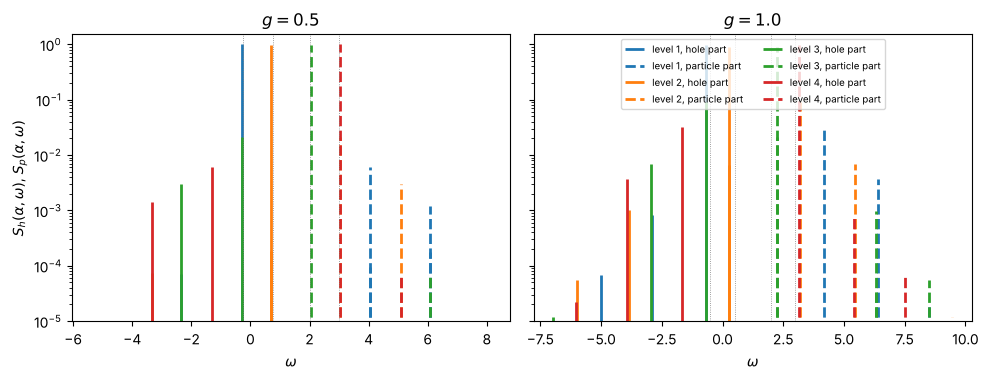

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), sharey=True)
for ax, g in zip(axes, (0.5, 1.0)):
    h, v, N = cc.pairing_model(levels=4, particles=4, g=g)
    lp = gf.LehmannPropagator(h, v, N)
    em, Sh = lp.hole_strength()
    ep, Sp = lp.particle_strength()
    colors = ["C0", "C1", "C2", "C3"]
    for level in range(4):
        a = 2 * level                     # the (level, +) spin orbital
        mask = Sh[:, a] > 1e-6
        ax.vlines(em[mask], 1e-6, Sh[mask, a], color=colors[level], lw=2,
                  label=f"level {level + 1}, hole part")
        mask = Sp[:, a] > 1e-6
        ax.vlines(ep[mask], 1e-6, Sp[mask, a], color=colors[level], lw=2,
                  ls="--", label=f"level {level + 1}, particle part")
    eps = np.diag(cc.fock_matrix(h, v, N))
    for e in eps[::2]:
        ax.axvline(e, color="gray", lw=0.6, ls=":")
    ax.set_yscale("log")
    ax.set_ylim(1e-5, 1.5)
    ax.set_xlabel(r"$\omega$")
    ax.set_title(f"$g={g}$")
axes[0].set_ylabel(r"$S_h(\alpha,\omega)$, $S_p(\alpha,\omega)$")
axes[1].legend(fontsize=7, ncol=2, loc="upper center")
plt.tight_layout()
plt.show()

The occupation numbers $n_\alpha=\int S_h(\alpha,\omega)d\omega$ as a function
of $g$: the hole levels are depleted, the particle levels populated, and the
total stays at four particles.

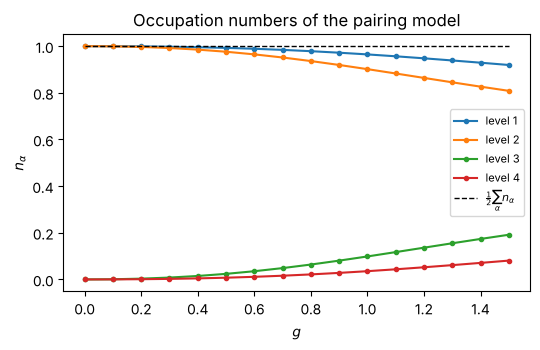

In [4]:
gs = np.linspace(0.0, 1.5, 16)
occ = []
for g in gs:
    h, v, N = cc.pairing_model(levels=4, particles=4, g=g)
    occ.append(gf.LehmannPropagator(h, v, N).occupation()[0][::2])
occ = np.array(occ)
fig, ax = plt.subplots(figsize=(5.5, 3.6))
for level in range(4):
    ax.plot(gs, occ[:, level], "o-", ms=3, label=f"level {level + 1}")
ax.plot(gs, occ.sum(1) / 2, "k--", lw=1, label=r"$\frac{1}{2}\sum_\alpha n_\alpha$")
ax.set_xlabel("$g$")
ax.set_ylabel(r"$n_\alpha$")
ax.set_title("Occupation numbers of the pairing model")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 2. The second-order self energy and the Dyson equation

With the self energy in pole form,
$\Sigma_{\alpha\beta}(\omega)=\Sigma^{(1)}_{\alpha\beta}+\sum_s M^{L}_{s\alpha}M^{R}_{s\beta}/(\omega-E_s)$,
the Dyson equation is equivalent to the eigenvalue problem of the extended
matrix with the Fock matrix in the upper-left block, the coupling vectors in
the off-diagonal blocks and the pole energies on the lower-right diagonal.
Its eigenvalues are the poles of $g$ and the top components of its
eigenvectors the spectroscopic amplitudes.  With $\Gamma=V$ the poles are
the $2p1h$ and $2h1p$ energies and the method is the second-order Green's
function (GF2).  The static part of the self energy is rebuilt from the
correlated density matrix until the energy is converged.

In [5]:
gf.demo_second_order()

The second-order self energy and the Dyson equation, pairing model
  48 poles of Sigma^(2); 2p1h poles at [3.25 4.25 5.25 6.25]  2h1p poles at [-3.5 -2.5 -1.5 -0.5]
  exact removal energies      [ 0.694   0.694  -0.2832 -0.2832 -0.2896 -0.2896 -1.2832 -1.2832 -1.5832 -1.5832 -1.5832 -1.5832 -1.5832 -1.5832
 -1.5832 -1.5832 -2.3407 -2.3407 -2.3522 -2.3522 -2.5832 -2.5832 -2.5832 -2.5832 -2.5832 -2.5832 -2.5832 -2.5832
 -3.3218 -3.3218 -3.3407 -3.3407 -3.5832 -3.5832 -3.5832 -3.5832 -3.5832 -3.5832 -3.5832 -3.5832]
  Dyson(GF2) removal energies [ 0.7147  0.7147 -0.2723 -0.2723 -0.5245 -0.5245 -1.5    -1.5   ]
  exact occupation  [0.99251 0.99251 0.97603 0.97603 0.02397 0.02397 0.00749 0.00749]
  Dyson(GF2)        [0.9955 0.9955 0.9874 0.9874 0.0126 0.0126 0.0045 0.0045]
  E_FCI = 1.41677428   E(GF2) = 1.43820334   cycles of the static self-consistency: 5


The exact hole spectral function against the GF2 one for the lowest hole
level and the lowest particle level of the pairing model at $g=1$.  For the
hole level GF2 has the quasiparticle peak only: the pure pairing interaction
has no $2h1p$ poles for a hole orbital (a hole and a particle never form a
time-reversed pair), so the exact satellites are of higher order.  For the
particle level the hole strength -- its occupation -- sits at the $2h1p$
energies, which GF2 has.

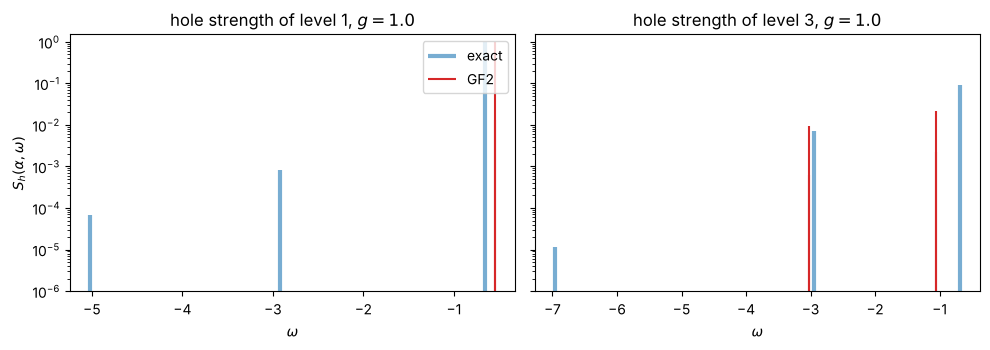

In [6]:
g = 1.0
h, v, N = cc.pairing_model(levels=4, particles=4, g=g)
lp = gf.LehmannPropagator(h, v, N)
res = gf.green_function_energy(h, v, N, scheme="gf2")
sol = res["dyson"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, a in zip(axes, (0, 4)):
    em, Sh = lp.hole_strength()
    mask = Sh[:, a] > 1e-7
    ax.vlines(em[mask], 1e-7, Sh[mask, a], color="C0", lw=3, alpha=0.6, label="exact")
    w = sol["poles"].real[sol["holes"]]
    S = sol["strength"].real[sol["holes"], a]
    mask = S > 1e-7
    ax.vlines(w[mask] + 0.03, 1e-7, S[mask], color="C3", lw=1.5, label="GF2")
    ax.set_yscale("log")
    ax.set_ylim(1e-6, 1.5)
    ax.set_xlabel(r"$\omega$")
    ax.set_title(f"hole strength of level {a // 2 + 1}, $g={g}$")
axes[0].set_ylabel(r"$S_h(\alpha,\omega)$")
axes[0].legend()
plt.tight_layout()
plt.show()

The self energy itself can be extracted from the exact propagator,
$\Sigma(\omega)=\omega-F-g(\omega)^{-1}$, and compared with the second-order
one.  Both have poles at the $2p1h$ energies above the Fermi level and at the
$2h1p$ energies below it; the exact one has more of them and its poles are
shifted.  Shown is the diagonal element of the lowest hole orbital of the
pairing plus particle-hole model, where the self energy is not diagonal.

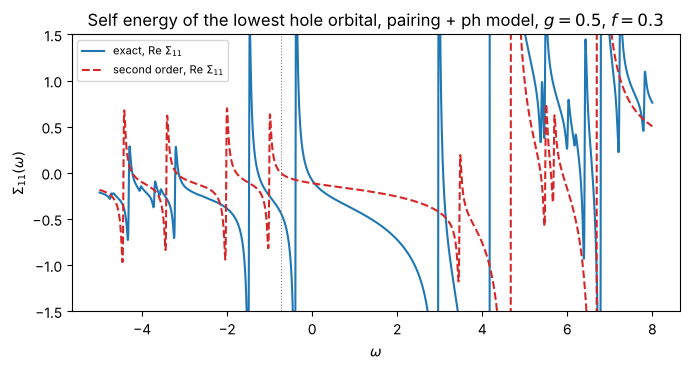

In [7]:
h, v, N = cc.pairing_ph_model(levels=4, particles=4, g=0.5, f=0.3)
hh, vv, C, _ = cc.hartree_fock(h, v, N)
F = cc.fock_matrix(hh, vv, N)
eps = np.diag(F)
lp = gf.LehmannPropagator(hh, vv, N)
E2, ML2, MR2 = gf.self_energy_poles(vv, vv, eps, N)
omegas = np.linspace(-5, 8, 2600)
exact = np.array([gf.exact_self_energy(lp, F, w, eta=0.02)[0, 0] for w in omegas])
second = np.array([gf.self_energy(w + 0.02j, F, E2, ML2, MR2)[0, 0] for w in omegas])
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(omegas, exact.real, "C0", label=r"exact, Re $\Sigma_{11}$")
ax.plot(omegas, second.real + F[0, 0] - F[0, 0], "C3--", label=r"second order, Re $\Sigma_{11}$")
ax.set_ylim(-1.5, 1.5)
ax.axvline(eps[0], color="gray", ls=":", lw=0.8)
ax.set_xlabel(r"$\omega$")
ax.set_ylabel(r"$\Sigma_{11}(\omega)$")
ax.set_title("Self energy of the lowest hole orbital, pairing + ph model, $g=0.5$, $f=0.3$")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 3. The two channels of the parquet equations are the two RPAs of chapter 7

In the [12] channel a ladder insertion is a matrix product in the space of
antisymmetric pairs $a<b$; in the [13] channel a ring insertion is a matrix
product in the space of ordered pairs $(p,q)$ with
$\tilde M_{(pq),(rs)}=\langle ps|M|qr\rangle$.  The pure series
$K+KGK+\cdots$ of a channel has its poles where $1-G(\Omega)K$ is singular,
and those are the eigenvalues of the particle-hole RPA matrix of chapter 7 for
the ring channel and of the particle-particle RPA matrix for the ladder
channel.  The check below is exact to machine precision.

In [8]:
gf.demo_channels()

The ring and ladder channels against the RPA (pairing + ph model, g = 0.4, f = 0.3, HF basis)
  RPA energies      [1.376762 1.376762 1.376762 1.376762 2.411596 2.411596 2.411596 2.411596 2.572631 2.572631 2.572631 2.572631 3.603075
 3.603075 3.603075 3.603075]
  ring-series poles [1.376762 1.376762 1.376762 1.376762 2.411596 2.411596 2.411596 2.411596 2.572631 2.572631 2.572631 2.572631 3.603075
 3.603075 3.603075 3.603075]
  largest difference 1.0658141036401503e-14
  pp-RPA energies     [-0.685914 -0.149862 -0.149862 -0.149862 -0.111622  2.126212  2.953482  4.941408  4.952009  4.952009  4.952009
  5.578581]
  ladder-series poles [-0.685914 -0.149862 -0.149862 -0.149862 -0.111622  2.126212  2.953482  4.941408  4.952009  4.952009  4.952009
  5.578581]
  largest difference 4.440892098500626e-15


## 4. Perturbative content

The sum rule with the second-order propagator and the self-consistent static
self energy reproduces the energy through second order; with the full energy
dependence of the ladder channel (the pp-RPA phonons), of the ring channel
(the ph-RPA phonons), or of both, it reproduces the energy through third
order.  The columns below are differences divided by the next power of $g$,
and they settle to constants.

In [9]:
gf.demo_perturbative_content()

Perturbative content: (E_method - E_MPn)/g^(n+1) for small g
  pairing model, 4 levels, 4 particles
     g     (GF2-MP2)/g^3  (GF2-MP3)/g^4  (lad-MP3)/g^4  (ring-MP3)/g^4  (both-MP3)/g^4


   0.025       0.00048         7.2464        -0.1284         7.2270        -0.1479
   0.050       0.00092         3.5671        -0.1277         3.5483        -0.1465
   0.100       0.00171         1.7292        -0.1265         1.7116        -0.1442


   0.200       0.00293         0.8137        -0.1253         0.7981        -0.1409


## 5. The pairing model: everything against everything

The energy-independent parquet vertex is evaluated at the starting energy
$E_{\rm in}=-10$, far from every pole of the two-time propagators, as in the
original work.  The columns `ladder-RPA`, `ring-RPA` and `both-RPA` are the
self energies with the full energy dependence of one channel or of both.

In [10]:
rows_pairing = gf.demo_pairing()

The pairing model, 4 levels, 4 particles (starting energy -10)


                  HF        MP2        MP3        GF2    parquet ladder-RPA   ring-RPA   both-RPA        CCD        FCI
g = 0.25    1.750000   1.733203   1.730787   1.733256   1.733372   1.730298   1.733198   1.730241   1.730456   1.730460
g = 0.50    1.500000   1.437607   1.421088   1.438203   1.439158   1.412795   1.437509   1.412096   1.416638   1.416774
g = 0.75    1.250000   1.118820   1.070482   1.121015   1.124286   1.017679   1.118265   1.014813   1.051571   1.052726
g = 1.00    1.000000   0.780952   0.680454   0.786152   0.793984   0.274554   0.779155   0.267237   0.630443   0.635548


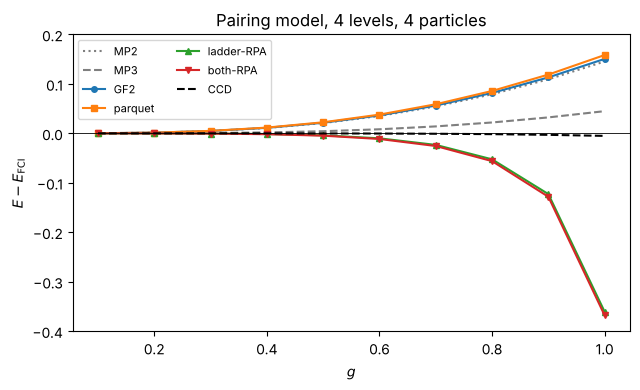

In [11]:
gs = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
keys = ["MP2", "MP3", "GF2", "parquet", "ladder-RPA", "both-RPA", "CCD"]
table = {k: [] for k in keys}
for g in gs:
    h, v, N = cc.pairing_model(levels=4, particles=4, g=g)
    out = gf.compare_methods(h, v, N)
    for k in keys:
        table[k].append(out[k] - out["FCI"])
fig, ax = plt.subplots(figsize=(6.5, 4))
styles = {"MP2": "C7:", "MP3": "C7--", "GF2": "C0o-", "parquet": "C1s-",
          "ladder-RPA": "C2^-", "both-RPA": "C3v-", "CCD": "k--"}
for k in keys:
    ax.plot(gs, table[k], styles[k], ms=4, label=k)
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("$g$")
ax.set_ylabel(r"$E-E_{\rm FCI}$")
ax.set_title("Pairing model, 4 levels, 4 particles")
ax.set_ylim(-0.4, 0.2)
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

## 6. The starting energy and the parameter $\eta$

The energy-independent scheme evaluates the two-time propagators at a fixed
energy $E_{\rm in}$, common to both channels.  Far from the poles the vertex
is close to the bare interaction and the result close to GF2; near a pole of
$G_0^{pphh}$ or $G_0^{ph}$ the iteration becomes unstable, and a finite
$\eta$ is needed to pass through.  The asterisks mark unconverged iterations.

In [12]:
gf.demo_starting_energy()

Dependence of the energy-independent parquet energy on the starting energy (pairing model, g = 0.5)
  GF2 1.438203   FCI 1.416774
   E_in    eta=0        eta=0.5
    -20   1.438491   1.438491


    -10   1.439158   1.439154
     -5   1.441073   1.441030


     -3   1.443665   1.443871
     -2   1.445589   1.446762


     -1   1.457136   1.453601
      0   1.370346   1.434458


      1   1.446885   1.443676


      2   1.518103*   1.416531


      3   1.467452*   1.399923
      5      --      1.434400


     10   1.441237   1.441187
     20   1.438694   1.438693


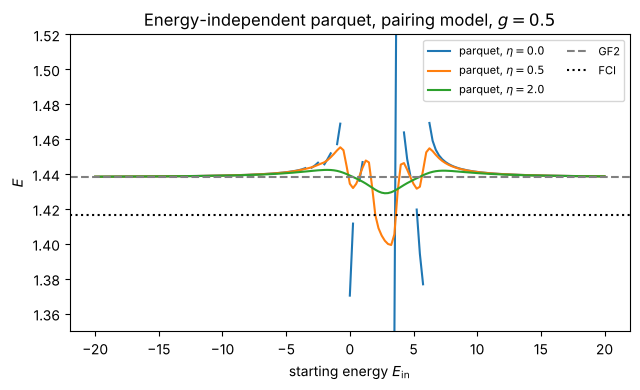

In [13]:
h, v, N = cc.pairing_model(levels=4, particles=4, g=0.5)
e_gf2 = gf.green_function_energy(h, v, N, scheme="gf2")["energy"].real
e_fci = cc.fci_energy(h, v, N)[0]
Eins = np.linspace(-20, 20, 161)
fig, ax = plt.subplots(figsize=(6.5, 4))
for eta, style in ((0.0, "C0-"), (0.5, "C1-"), (2.0, "C2-")):
    es = []
    for Ein in Eins:
        try:
            r = gf.green_function_energy(h, v, N, scheme="parquet",
                                         omega_pp=Ein, omega_ph=Ein, eta=eta)
            es.append(r["energy"].real if r["vertex_info"]["converged"] else np.nan)
        except (np.linalg.LinAlgError, ValueError):
            es.append(np.nan)
    ax.plot(Eins, es, style, label=rf"parquet, $\eta={eta}$")
ax.axhline(e_gf2, color="gray", ls="--", label="GF2")
ax.axhline(e_fci, color="k", ls=":", label="FCI")
ax.set_ylim(1.35, 1.52)
ax.set_xlabel(r"starting energy $E_{\rm in}$")
ax.set_ylabel("$E$")
ax.set_title("Energy-independent parquet, pairing model, $g=0.5$")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

## 7. The pairing plus particle-hole model

The same parameter sets as the CCSD table of the coupled-cluster chapter.  The pair-breaking
term makes the self energy non-diagonal and activates the ring channel.  The
particle number $\mathrm{Tr}\,\rho$ of each Dyson solution is a useful
diagnostic: it is exactly four for the pure pairing model and drifts away
from four when a scheme breaks down.

In [14]:
rows_ph = gf.demo_pairing_ph()
print()
print("particle number of the Dyson solutions at g = 0.5:")
for f in (0.1, 0.2, 0.25, 0.3):
    h, v, N = cc.pairing_ph_model(levels=4, particles=4, g=0.5, f=f)
    hh, vv, _, _ = cc.hartree_fock(h, v, N)
    ns = []
    for s in ("gf2", "ladder-rpa", "both-rpa"):
        r = gf.green_function_energy(hh, vv, N, basis="reference", scheme=s)
        ns.append(f"{s} {np.trace(r['density']).real:.4f}")
    print(f"  f = {f:4.2f}:  " + "   ".join(ns))

The pairing plus particle-hole model (starting energy -10)


                             HF        MP2        GF2    parquet   both-RPA        CCD       CCSD        FCI
g = 0.50, f = 0.025    1.449271   1.374627   1.375445   1.376748   1.339668   1.346912   1.346909   1.347133
g = 0.70, f = 0.050    1.197086   1.049140   1.051807   1.055987   0.912693   0.968186   0.968164   0.969759
g = 1.00, f = 0.050    0.897086   0.637849   0.644650   0.655432   0.334811   0.442445   0.442412   0.450582
g = 0.50, f = 0.250    0.928620   0.698663   0.703575   0.719282   0.171018   0.547897   0.547274   0.551192
g = 1.00, f = 0.500   -0.269764  -0.972193  -0.947687  -0.802812  -1.663232  -1.777932  -1.780542  -1.691737

particle number of the Dyson solutions at g = 0.5:


  f = 0.10:  gf2 4.0000   ladder-rpa 3.9996   both-rpa 3.9996


  f = 0.20:  gf2 3.9999   ladder-rpa 3.9954   both-rpa 3.9953


  f = 0.25:  gf2 3.9998   ladder-rpa 3.9858   both-rpa 3.9855


  f = 0.30:  gf2 3.9997   ladder-rpa 3.8686   both-rpa 3.8762


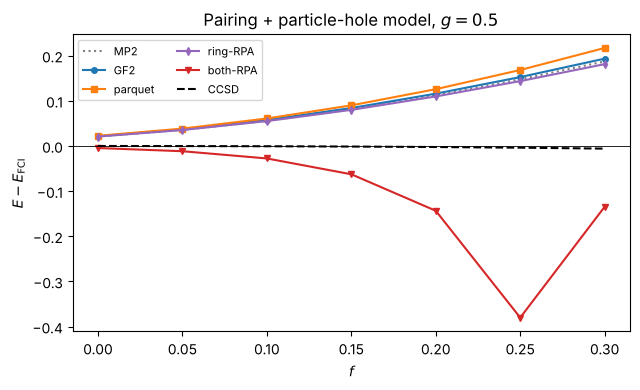

In [15]:
fs = np.array([0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3])
keys = ["MP2", "GF2", "parquet", "ring-RPA", "both-RPA", "CCSD"]
table = {k: [] for k in keys}
for f in fs:
    h, v, N = cc.pairing_ph_model(levels=4, particles=4, g=0.5, f=f)
    out = gf.compare_methods(h, v, N)
    for k in keys:
        table[k].append(out[k] - out["FCI"])
fig, ax = plt.subplots(figsize=(6.5, 4))
styles = {"MP2": "C7:", "GF2": "C0o-", "parquet": "C1s-", "ring-RPA": "C4d-",
          "both-RPA": "C3v-", "CCSD": "k--"}
for k in keys:
    ax.plot(fs, table[k], styles[k], ms=4, label=k)
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("$f$")
ax.set_ylabel(r"$E-E_{\rm FCI}$")
ax.set_title("Pairing + particle-hole model, $g=0.5$")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

## 8. The Lipkin model

The Lipkin interaction moves pairs of particles between the two levels, so
the ladder channel is nearly inactive and the physics is in the ring channel,
whose collectivity grows with $\chi=V(N-1)/\varepsilon$.  For $N=4$ the
second-order Dyson equation is exact (see the chapter for why); for larger
$N$ it is not, and the ring-dressed self energy over-corrects as $\chi$
approaches one.

In [16]:
rows_lipkin = gf.demo_lipkin()

The Lipkin model (starting energy -10)


                         HF        MP2        GF2    parquet   ring-RPA   both-RPA        CCD       CCSD        FCI
N = 4, V = 0.10   -2.000000  -2.030000  -2.029778  -2.029751  -2.030394  -2.030468  -2.029778  -2.029778  -2.029778
N = 4, V = 0.30   -2.000000  -2.270000  -2.253886  -2.251947  -2.348884  -2.354934  -2.253886  -2.253886  -2.253886
N = 4, V = 0.60   -2.000000  -3.080000  -2.884441  -2.860916  -2.891764  -2.959049  -2.884441  -2.884441  -2.884441
N = 6, V = 0.10   -3.000000  -3.075000  -3.074085  -3.073916  -3.078694  -3.078878  -3.075571  -3.075571  -3.075505
N = 6, V = 0.15   -3.000000  -3.168750  -3.164253  -3.163421  -3.193444  -3.194371  -3.171698  -3.171698  -3.170957
N = 8, V = 0.10   -4.000000  -4.140000  -4.137632  -4.137019  -4.158094  -4.158437  -4.146517  -4.146517  -4.145780


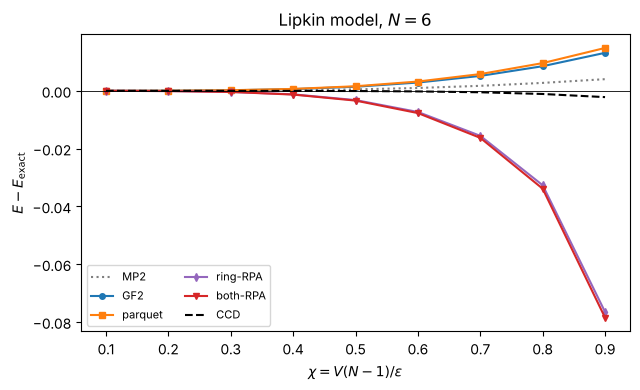

In [17]:
Vs = np.linspace(0.02, 0.18, 9)
keys = ["MP2", "GF2", "parquet", "ring-RPA", "both-RPA", "CCD"]
table = {k: [] for k in keys}
for V in Vs:
    h, v, N = gf.lipkin_model(N=6, V=V)
    out = gf.compare_methods(h, v, N, fci=gf.lipkin_exact_energy(6, V=V), mp3=False)
    for k in keys:
        table[k].append(out[k] - out["FCI"])
fig, ax = plt.subplots(figsize=(6.5, 4))
styles = {"MP2": "C7:", "GF2": "C0o-", "parquet": "C1s-", "ring-RPA": "C4d-",
          "both-RPA": "C3v-", "CCD": "k--"}
for k in keys:
    ax.plot(Vs * 5, table[k], styles[k], ms=4, label=k)
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel(r"$\chi = V(N-1)/\varepsilon$")
ax.set_ylabel(r"$E-E_{\rm exact}$")
ax.set_title("Lipkin model, $N=6$")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

The hole spectral function of the Lipkin model with $N=6$: the lower level
keeps most of its strength, and the removal strength that leaks into the
upper level sits at the $2h1p$ energies.  GF2 reproduces the main peaks and
the first satellites.

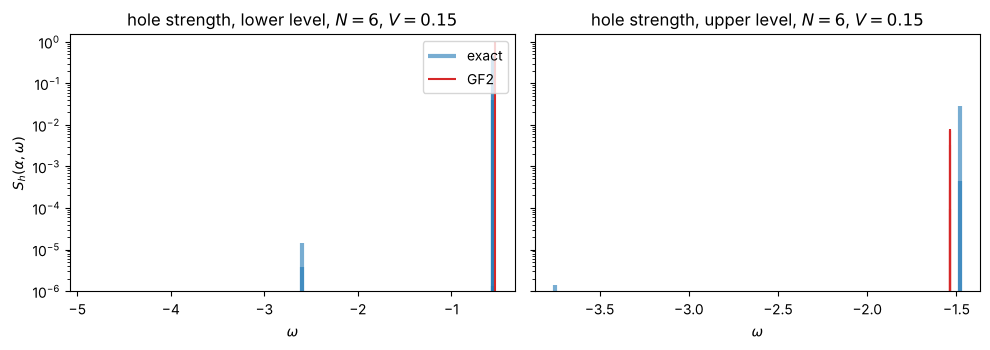

In [18]:
h, v, N = gf.lipkin_model(N=6, V=0.15)
lp = gf.LehmannPropagator(h, v, N)
res = gf.green_function_energy(h, v, N, scheme="gf2")
sol = res["dyson"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, a, name in zip(axes, (0, N), ("lower level", "upper level")):
    em, Sh = lp.hole_strength()
    mask = Sh[:, a] > 1e-7
    ax.vlines(em[mask], 1e-7, Sh[mask, a], color="C0", lw=3, alpha=0.6, label="exact")
    w = sol["poles"].real[sol["holes"]]
    S = sol["strength"].real[sol["holes"], a]
    mask = S > 1e-7
    ax.vlines(w[mask] + 0.02, 1e-7, S[mask], color="C3", lw=1.5, label="GF2")
    ax.set_yscale("log")
    ax.set_ylim(1e-6, 1.5)
    ax.set_xlabel(r"$\omega$")
    ax.set_title(f"hole strength, {name}, $N=6$, $V=0.15$")
axes[0].set_ylabel(r"$S_h(\alpha,\omega)$")
axes[0].legend()
plt.tight_layout()
plt.show()

## 9. Quasiparticle self-consistency

So far only the static self energy was made self-consistent.  Replacing also
the single-particle energies that enter the two-time propagators and the
self-energy poles by the dominant poles of the previous Dyson solution damps
the over-correction of the RPA-dressed self energies at strong coupling.

In [19]:
print(" g   scheme        static sc     + qp energies     CCD        FCI")
for g in (0.5, 1.0):
    h, v, N = cc.pairing_model(levels=4, particles=4, g=g)
    hh, vv, _, _ = cc.hartree_fock(h, v, N)
    f = cc.fock_matrix(hh, vv, N)
    ccd = cc.reference_energy(hh, vv, N) + cc.ccd(f, vv, N)["energy"]
    fci = cc.fci_energy(h, v, N)[0]
    for s in ("gf2", "ladder-rpa", "both-rpa"):
        r1 = gf.green_function_energy(h, v, N, scheme=s)
        r2 = gf.green_function_energy(h, v, N, scheme=s, update_energies=True, mixing=0.3)
        print(f"{g:4.2f} {s:12s} {r1['energy'].real:12.6f} {r2['energy'].real:14.6f}"
              f" {ccd:12.6f} {fci:10.6f}")

 g   scheme        static sc     + qp energies     CCD        FCI
0.50 gf2              1.438203       1.438217     1.416638   1.416774
0.50 ladder-rpa       1.412795       1.413866     1.416638   1.416774


0.50 both-rpa         1.412096       1.413225     1.416638   1.416774
1.00 gf2              0.786152       0.786950     0.630443   0.635548
1.00 ladder-rpa       0.274554       0.586439     0.630443   0.635548


1.00 both-rpa         0.267237       0.582345     0.630443   0.635548


## Summary

* The Lehmann representation, the spectral functions and the sum rules of the
  chapter are checked against full configuration interaction to machine
  precision.
* The Dyson equation with a pole-form self energy is an eigenvalue problem in
  an extended space; with the second-order self energy it reproduces the main
  peaks and first satellites of the spectral function and the energy through
  second order, and for the Lipkin model with $N=4$ it is exact.
* The ladder and ring channels of the parquet equations are the pp-RPA and
  the ph-RPA; evaluated at a fixed starting energy far from their poles they
  change the second-order result little, as in the original parquet study of
  the pairing model, while their full energy dependence (through the RPA
  phonons) carries the third order and over-corrects as the RPA modes soften.